In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
r0 = [10,50,100]
c = [1,2,3]
lamb = [0.5, 1, 2]
k = [0.5,1,2]

Zestaw nr. 1 

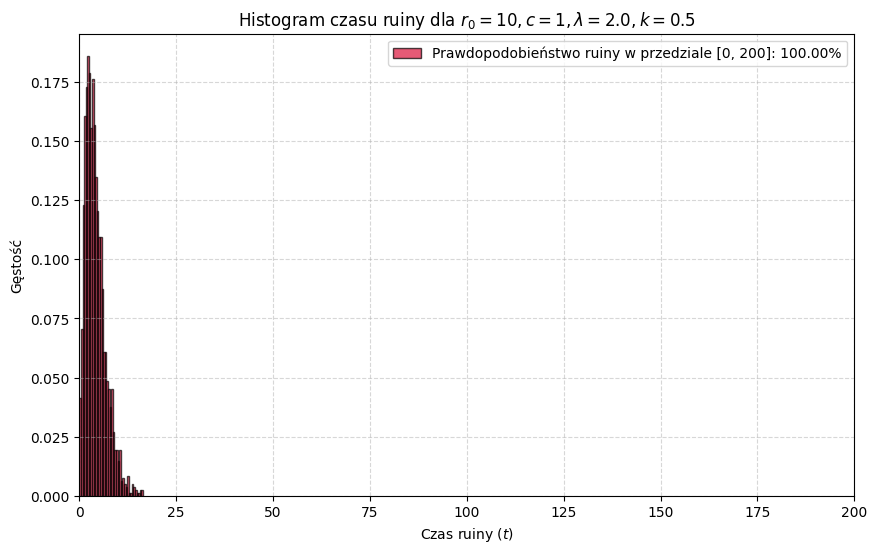

średni czas ruiny: 4.104025565953584, odchylenie stand.: 2.632295652390352


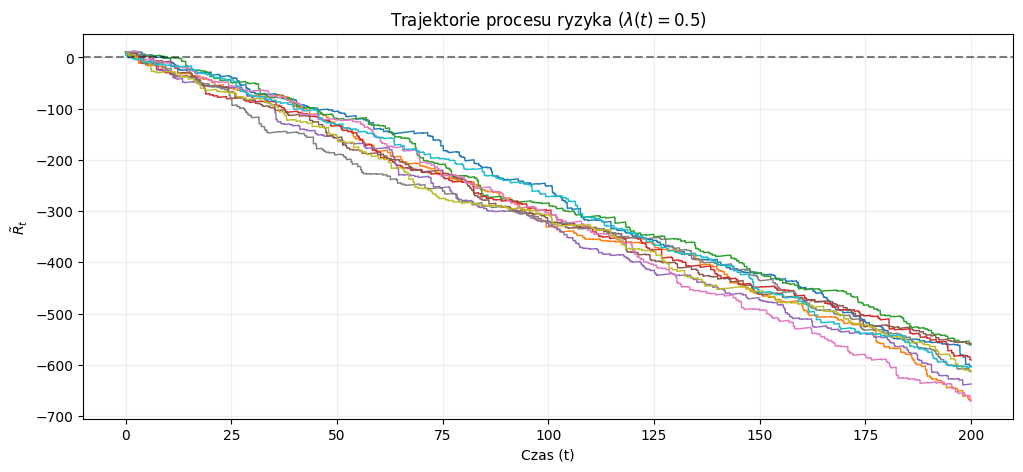

In [ ]:


lamb_poisson = 2.0  
c = 1               
r0 = 10             
k = 0.5             
T_max = 200         
trials = 2000      

def hist_ruin_time(lamb_poisson, c,r0,k,T_max,trials):
    
    ruin_times = []


    for i in range(trials):
        
        S, J = NHPP_thining_expon(M=lamb_poisson, T=T_max, func=lambda x: lamb_poisson, lamb=k)

        if len(S) > 0:
            
            capital_at_jumps = r0 + c * S - J

           
            ruin_indices = np.where(capital_at_jumps <= 0)[0]

            if len(ruin_indices) > 0:
                
                first_ruin_idx = ruin_indices[0]
                ruin_times.append(S[first_ruin_idx])
           
            
    plt.figure(figsize=(10, 6))
    
    plt.hist(ruin_times, bins=40, color='crimson', edgecolor='black', alpha=0.7, density=True)

    plt.title(f"Histogram czasu ruiny dla $r_0={r0}, c={c}, \\lambda={lamb_poisson}, k={k}$")
    plt.xlabel("Czas ruiny ($t$)")
    plt.ylabel("Gęstość")
    plt.xlim(0, T_max)
    plt.grid(True, linestyle='--', alpha=0.5)

    ruin_probability = len(ruin_times) / trials
    plt.legend([f"Prawdopodobieństwo ruiny w przedziale [0, {T_max}]: {ruin_probability:.2%}"], loc='upper right')

    plt.show()
    return np.mean(ruin_times), np.std(ruin_times)

mean, std = hist_ruin_time(lamb_poisson, c,r0,k,T_max,trials)
print(f"średni czas ruiny: {mean}, odchylenie stand.: {std}")
plot_trajectories(lambda x: lamb_poisson, lamb=k, T=T_max, M=lamb_poisson, r0=r0,c=c, num_paths=10)

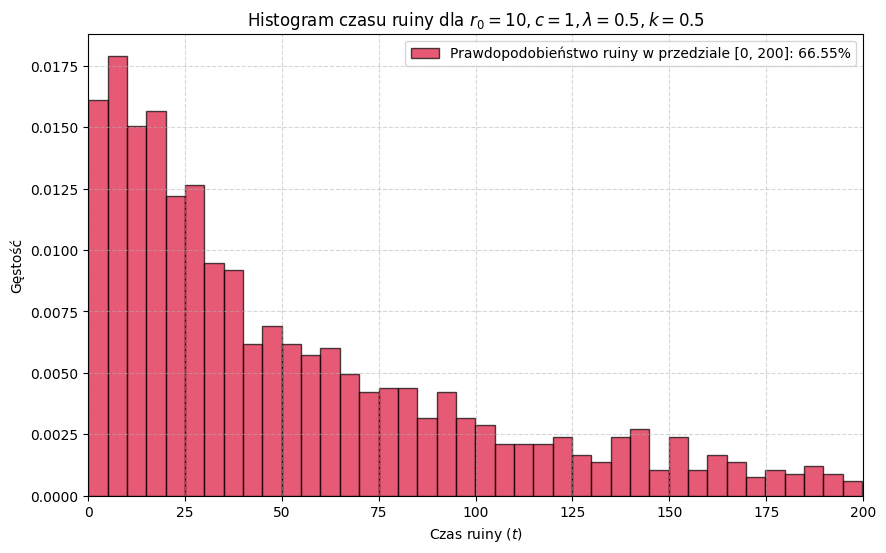

średni czas ruiny: 52.11131355180567, odchylenie stand.: 47.272028794624106


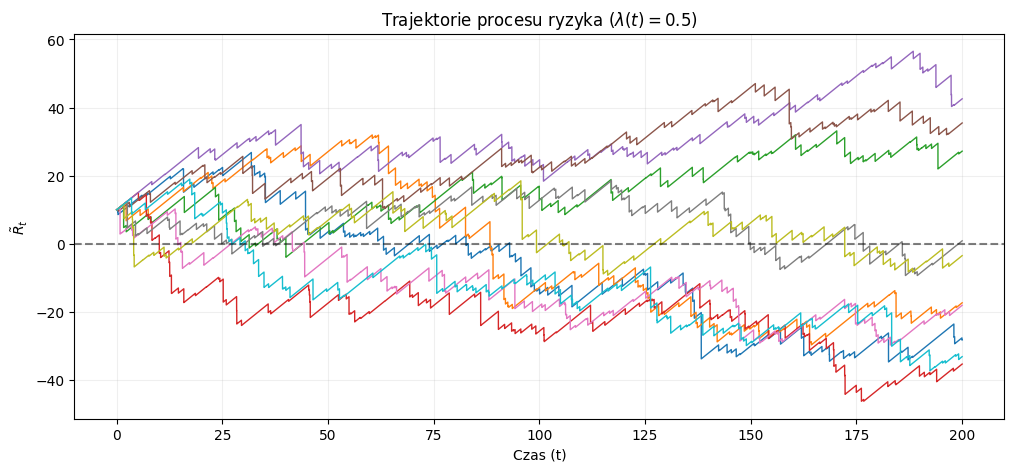

In [ ]:
lamb_poisson = 0.5 
c = 1              
r0 = 10            
k = 0.5            
T_max = 200         
trials = 2000

mean, std = hist_ruin_time(lamb_poisson, c,r0,k,T_max,trials)
print(f"średni czas ruiny: {mean}, odchylenie stand.: {std}")
plot_trajectories(lambda x: lamb_poisson, lamb=k, T=T_max, M=lamb_poisson, r0=r0,c=c, num_paths=10)

### Interpretacja 
Zmniejszenie intenstywności skoków (parametr lambda) istotnie zmniejszyło liczbę bankructw. średni moment bankructwa z ok. 4 zmienił się na ok.50 zwiększyło się również odchylenie standardowe momentu bankructwa co oznacza, co jest zgodne z tym że sporo firm bankrutowało pod koniec czasu T. W pierwszym przykładzie wszystkie firmy bankrutowały bardzo szybko, nie dochodząc do końca czasu.

## Zadanie 2. 


In [5]:
def parisian_ruin(lamb_func, lamb, T_list, M, r0, c, num_paths=100000, parisian_time=1):
    """Function that calculates probability of bankrupcy but we are bankrupt if we stay more than ruin_time below zero

    Args:
        lamb_func (function): function that returns lamb parameter for jumps
        lamb (float>0): parameter for exponential jumps
        T_list (list): where we meausure bankrupcy
        M (float): inifmum for lamb func (for thinning)
        r0 (float): initial capital
        c (float): "a" for liniear function
        num_paths (int, optional): number of paths. Defaults to 100000.
        ruin_time (int, optional): defines how long we have to stay below zero to become bankrupt. Defaults to 1.
    """    """"""
    bankrupt_counts = {t: 0 for t in T_list}

    for _ in range(num_paths):
        # Generating trajectory for max T 
        max_T = max(T_list)
        S, J = NHPP_thining_expon(M, max_T, lamb_func, lamb=lamb)
        is_bankrupt = False # new trajectory

        if len(S) > 0:
            # we can only become bankrupt at moments of jumps
            # calculate capital at jumps
            capital_at_jumps = r0 + c * S - J
            
            # check for each time period
            for t in T_list:
                # jumps to time t
                mask_s_j = S <= t # mask used for S, J

                time_under_zero = 0
                if is_bankrupt:
                    bankrupt_counts[t] += 1
                else:
                    for i in range(1, len(S[mask_s_j])):
                        t_start = S[mask_s_j][i-1]
                        t_end = S[mask_s_j][i]

                        capital_start = capital_at_jumps[mask_s_j][i-1] # 
                        capital_end = capital_start + c * (t_end-t_start)# adding the next jump - capital just before jump

                        if capital_start <= 0 and capital_end <= 0:
                            time_under_zero += t_end - t_start
                            if time_under_zero >  parisian_time:
                                bankrupt_counts[t] += 1
                                is_bankrupt = True
                                break

                        elif capital_start <= 0 and capital_end >= 0:
                            time_under_zero += -capital_start/c
                            if time_under_zero > parisian_time:
                                bankrupt_counts[t] += 1
                                is_bankrupt = True
                                break
                            time_under_zero = 0
                        else:
                            time_under_zero=0
    return {t: count / num_paths for t, count in bankrupt_counts.items()}

print(probability_of_bankrupcy(lambda x: 100, 10, [10, 50, 100], 1, 1, 0.1, num_paths=1000))
print(parisian_ruin(lambda x: 100, 10, [10, 50, 100], 1, 1, 0.1, num_paths=1000))

{10: 0.053, 50: 0.3, 100: 0.422}
{10: 0.022, 50: 0.259, 100: 0.415}


porównanie różnych czasów ruiny paryskiej dla procesu ryzyka z wyżej 

In [6]:
print("klasyczna ruina")
print(probability_of_bankrupcy(lambda x: 100, 10, [10, 50, 100], 1, 1, 0.1, num_paths=1000))
parisian_times = [1,2,5,10]
for i in parisian_times:
    print(f"paryska ruina dla parisian ruin = {i}")
    print(parisian_ruin(lambda x: 100, 10, [10, 50, 100], 1, 1, 0.1, num_paths=1000, parisian_time=i))

klasyczna ruina
{10: 0.041, 50: 0.294, 100: 0.436}
paryska ruina dla parisian ruin = 1
{10: 0.015, 50: 0.24, 100: 0.403}
paryska ruina dla parisian ruin = 2
{10: 0.014, 50: 0.234, 100: 0.385}
paryska ruina dla parisian ruin = 5
{10: 0.002, 50: 0.16, 100: 0.315}
paryska ruina dla parisian ruin = 10
{10: 0.0, 50: 0.114, 100: 0.258}


## Interpretacja 
Zwiększenie czasu ruiny paryskiej zmniejsza szanse bankructwa. 

In [7]:
def parisian_ruin_times(lamb_func, lamb, T_max, M, r0, c, num_paths=2000, parisian_time=1):
    ruin_times = []
    for _ in range(num_paths):
        S, J = NHPP_thining_expon(M, T_max, lamb_func, lamb=lamb)
        
        if len(S) > 0:
            # we can only become bankrupt at moments of jumps
            # calculate capital at jumps
            capital_at_jumps = r0 + c * S - J
            S_events = np.concatenate(([0], S, [T_max]))
            cap_events = np.concatenate(([r0], capital_at_jumps, [capital_at_jumps[-1]]))

            exact_ruin_time = None
            time_under_zero = 0

            for i in range(1, len(S_events)):
                t_start = S_events[i-1]
                t_end = S_events[i]

                capital_start = cap_events[i-1]
                capital_end = capital_start + c * (t_end - t_start)

                if capital_start < 0 and capital_end < 0:
                    time_under_zero += t_end - t_start
                    if time_under_zero > parisian_time:
                        exact_ruin_time = t_end - (time_under_zero - parisian_time)
                        break
                
                elif capital_start < 0 and capital_end > 0:
                    time_under_zero += -capital_start/c
                    if time_under_zero > parisian_time:
                        exact_ruin_time = t_end - (time_under_zero - parisian_time)
                        break
                    time_under_zero = 0
                else: 
                    time_under_zero =0
        if exact_ruin_time is not None:
            ruin_times.append(exact_ruin_time)
            
    return np.array(ruin_times)

            


In [8]:
num_paths = 1000

def hist_parisian_ruin(lambda_poisson,lamb,T_max, M, r0,c, num_paths=10_000, parisian_time=1):
    """plots the histogram for parisian ruin. returns empty histogram if there were no ruin 

    Args:
        lambda_poisson (_type_): _description_
        lamb (_type_): _description_
        T_max (_type_): _description_
        M (_type_): _description_
        r0 (_type_): _description_
        c (_type_): _description_
        num_paths (_type_, optional): _description_. Defaults to 10_000.
        parisian_time (int, optional): _description_. Defaults to 1.
    """    
    to_hist = parisian_ruin_times(lambda_poisson, lamb, T_max, M, r0, c, num_paths=num_paths, parisian_time=parisian_time)
    plt.hist(to_hist, bins=len(to_hist)//5, edgecolor="black", density=True)
    plt.grid(True, linestyle='--', alpha=0.5, zorder=0)

    parisian_ruin_probability = len(to_hist) / num_paths
    mean_ruin_time = np.mean(to_hist)
    std_ruin_time = np.std(to_hist)

    plt.title(f"Histogram czasu wystąpienia ruiny paryskiej dla czasu {parisian_time}", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Czas zajścia ruiny paryskiej ($t$)", fontsize=12)
    plt.ylabel("Gęstość częstości", fontsize=12)
    legend_text = (
            f"Prawd. ruiny paryskiej: {parisian_ruin_probability:.2%}\n"
            f"Średni czas ruiny: {mean_ruin_time:.2f}\n"
            f"Odchylenie std: {std_ruin_time:.2f}"
        )
    plt.legend([legend_text], loc='upper right', fontsize=11, frameon=True)
    plt.tight_layout()
    plt.show()

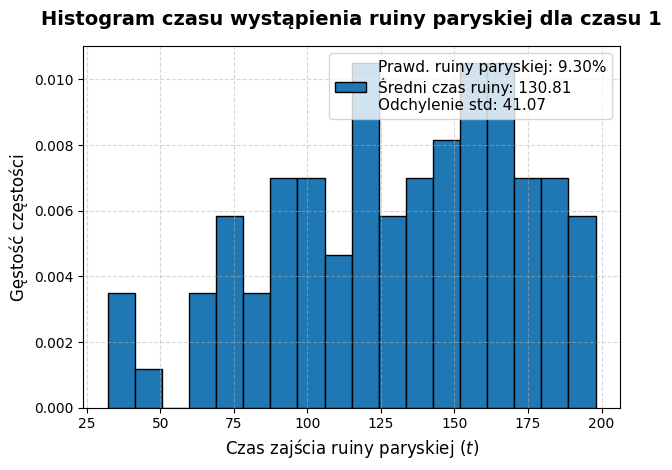

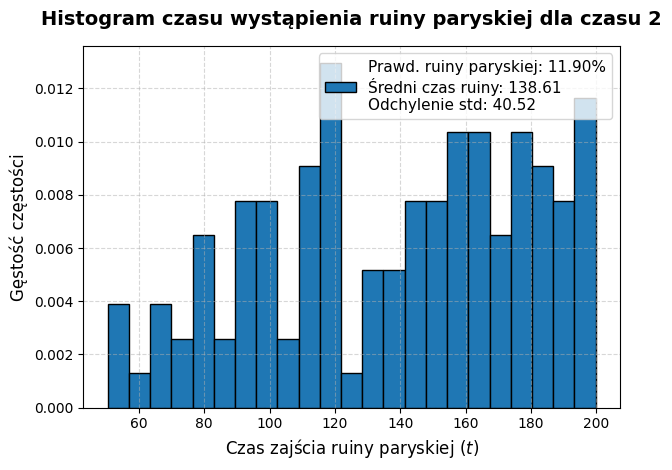

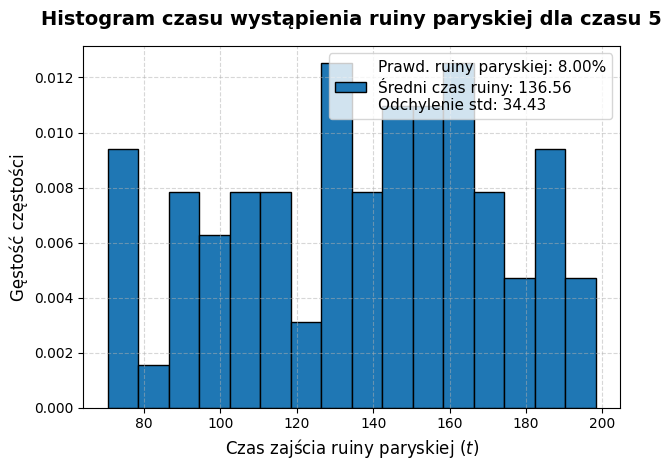

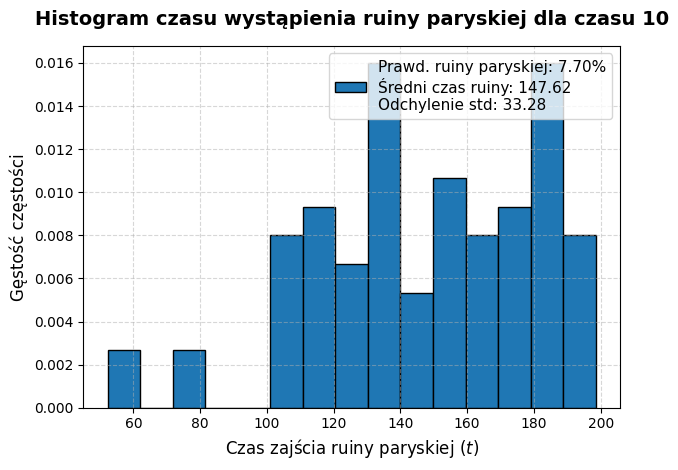

In [9]:
lamb = 10
T_max = 200
M = 10
r0 = 10
c = 1 

for i in parisian_times:
    hist_parisian_ruin(lambda x: 10, lamb, T_max, M, r0, c, num_paths=1000, parisian_time=i)

## Zadanie 4. 
Nariazie skip


In [18]:
# implementujemy wariant B 

def mixed_poisson(num_paths, T_max=200):
    """_summary_

    Args:
        size (_type_): _description_
        expon_1 (bool, optional): _description_. Defaults to False.
    """    
    
    lambdas = np.random.uniform(0,10,size=num_paths)
    n_per_path = np.random.poisson( lambdas * T_max, size=num_paths)

    path_indices = np.repeat(np.arange(num_paths), n_per_path)

    total_jumps = np.sum(n_per_path)
    S_all = np.random.uniform(0, T_max, size=total_jumps)

    sort_order = np.lexsort((S_all, path_indices)) # sorts firstly by path and then by time (S)
    S_all = S_all[sort_order] # applying the sort order
    path_indices = path_indices[sort_order] # also apply the sort order
    _, J_counts = np.unique(path_indices, return_counts=True)
    # np.cumsum i np.repeat pozwalają wygenerować sekwencje [1,2,3, 1,2, 1,2,3,4...] bez pętli
    N_all = np.arange(total_jumps) - np.repeat(np.cumsum(np.concatenate(([0], J_counts[:-1]))), J_counts) + 1
    """The number of jumps of each trajectory, """
    return S_all, N_all, path_indices, n_per_path

def mixed_poisson_exp(num_paths, T_max=200):
    """_summary_

    Args:
        size (_type_): _description_
        expon_1 (bool, optional): _description_. Defaults to False.
    """    
    
    lambdas = np.random.exponential(1,size=num_paths)
    n_per_path = np.random.poisson( lambdas * T_max, size=num_paths)

    path_indices = np.repeat(np.arange(num_paths), n_per_path)

    total_jumps = np.sum(n_per_path)
    S_all = np.random.uniform(0, T_max, size=total_jumps)

    sort_order = np.lexsort((S_all, path_indices)) # sorts firstly by path and then by time (S)
    S_all = S_all[sort_order] # applying the sort order
    path_indices = path_indices[sort_order] # also apply the sort order
    _, J_counts = np.unique(path_indices, return_counts=True)
    # np.cumsum i np.repeat pozwalają wygenerować sekwencje [1,2,3, 1,2, 1,2,3,4...] bez pętli
    N_all = np.arange(total_jumps) - np.repeat(np.cumsum(np.concatenate(([0], J_counts[:-1]))), J_counts) + 1
    """The number of jumps of each trajectory, """
    return S_all, N_all, path_indices, n_per_path

def mixed_poisson_pareto(num_paths, T_max=200):
    """_summary_

    Args:
        size (_type_): _description_
        expon_1 (bool, optional): _description_. Defaults to False.
    """    
    
    lambdas = np.random.pareto(2,size=num_paths)
    n_per_path = np.random.poisson( lambdas * T_max, size=num_paths)

    path_indices = np.repeat(np.arange(num_paths), n_per_path)

    total_jumps = np.sum(n_per_path)
    S_all = np.random.uniform(0, T_max, size=total_jumps)

    sort_order = np.lexsort((S_all, path_indices)) # sorts firstly by path and then by time (S)
    S_all = S_all[sort_order] # applying the sort order
    path_indices = path_indices[sort_order] # also apply the sort order
    _, J_counts = np.unique(path_indices, return_counts=True)
    # np.cumsum i np.repeat pozwalają wygenerować sekwencje [1,2,3, 1,2, 1,2,3,4...] bez pętli
    N_all = np.arange(total_jumps) - np.repeat(np.cumsum(np.concatenate(([0], J_counts[:-1]))), J_counts) + 1
    """The number of jumps of each trajectory, """
    return S_all, N_all, path_indices, n_per_path

print(mixed_poisson(3))
    

(array([  0.21524277,   0.57133462,   0.68287248, ..., 199.75020441,
       199.78013502, 199.99258933], shape=(3118,)), array([   1,    2,    3, ..., 1092, 1093, 1094], shape=(3118,)), array([0, 0, 0, ..., 2, 2, 2], shape=(3118,)), array([ 836, 1188, 1094], dtype=int32))


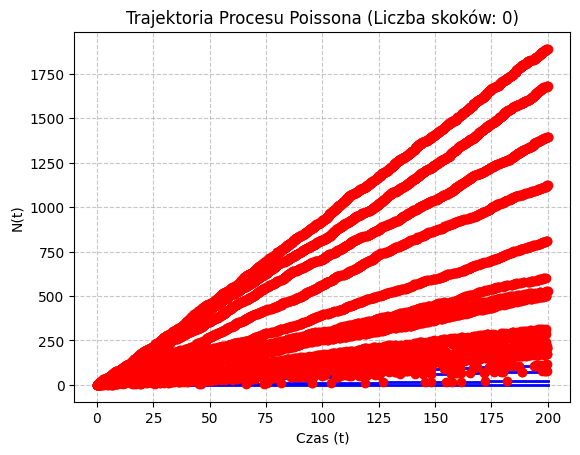

In [42]:
S_all_1, N_all_1, path_indices_1, n_per_path_1 = mixed_poisson(10)
S_all_2, N_all_2, path_indices_2, n_per_path_2 = mixed_poisson_exp(10)
for i in range(10):
    mask = path_indices_1 == i 
    S_path = S_all_1[mask]
    plot_poisson(S_path, T=200)
for i in range(10):
    mask = path_indices_2 == i 
    S_path = S_all_2[mask]
    plot_poisson(S_path,T=200) 

Lambda jest z rokładu U(0, 10)


<Figure size 1200x700 with 0 Axes>

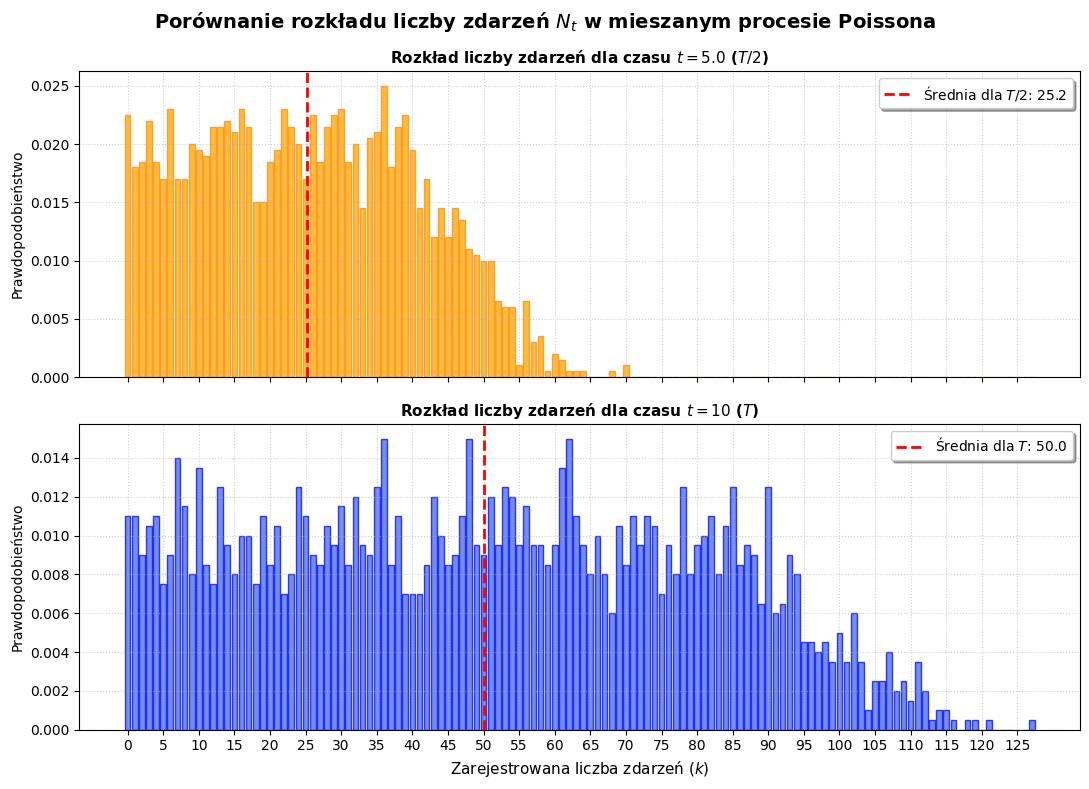

In [ ]:
K = 2000
T = 10

S_all, N_all, path_ids, n_per_path = mixed_poisson(num_paths=K, T_max=T)

plt.figure(figsize=(12, 7))

# 
N_events_T = []
N_events_T_2 = []
for path_id in range(K):

    # for T 
    mask = path_ids == path_id
    S_path = S_all[mask]
    N_path = N_all[mask]
    if len(N_path) > 0:
        N_events_T.append(N_path[-1])
    else:
        N_events_T.append(0)

    # for T/2
    mask_T_2 = S_path < T/2
    S_path = S_path[mask_T_2]
    N_path = N_path[mask_T_2]
    if len(N_path) > 0:
        N_events_T_2.append(N_path[-1])
    else:
        N_events_T_2.append(0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# same bins 
max_val = max(max(N_events_T), max(N_events_T_2))
bins = np.arange(0, max_val + 2) - 0.5
ticks_step = 2 if max_val < 30 else 5

# first plot
ax1.hist(N_events_T_2, bins=bins, density=True, color='orange', 
         edgecolor='darkorange', alpha=0.75, rwidth=0.8)
ax1.axvline(np.mean(N_events_T_2), color='red', linestyle='--', linewidth=2, 
            label=f'Średnia dla $T/2$: {np.mean(N_events_T_2):.1f}')

ax1.set_title(f"Rozkład liczby zdarzeń dla czasu $t = {T/2}$ ($T/2$)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Prawdopodobieństwo", fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, shadow=True)

# second plot
ax2.hist(N_events_T, bins=bins, density=True, color='royalblue', 
         edgecolor='blue', alpha=0.75, rwidth=0.8)
ax2.axvline(np.mean(N_events_T), color='red', linestyle='--', linewidth=2, 
            label=f'Średnia dla $T$: {np.mean(N_events_T):.1f}')

ax2.set_title(f"Rozkład liczby zdarzeń dla czasu $t = {T}$ ($T$)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Zarejestrowana liczba zdarzeń ($k$)", fontsize=11)
ax2.set_ylabel("Prawdopodobieństwo", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, shadow=True)


plt.xticks(np.arange(0, max_val + 1, step=ticks_step))

plt.suptitle("Porównanie rozkładu liczby zdarzeń $N_t$ w mieszanym procesie Poissona", fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout()
plt.show()

Lambda jest z rozkładu Wykładniczego EXP(1)

<Figure size 1200x700 with 0 Axes>

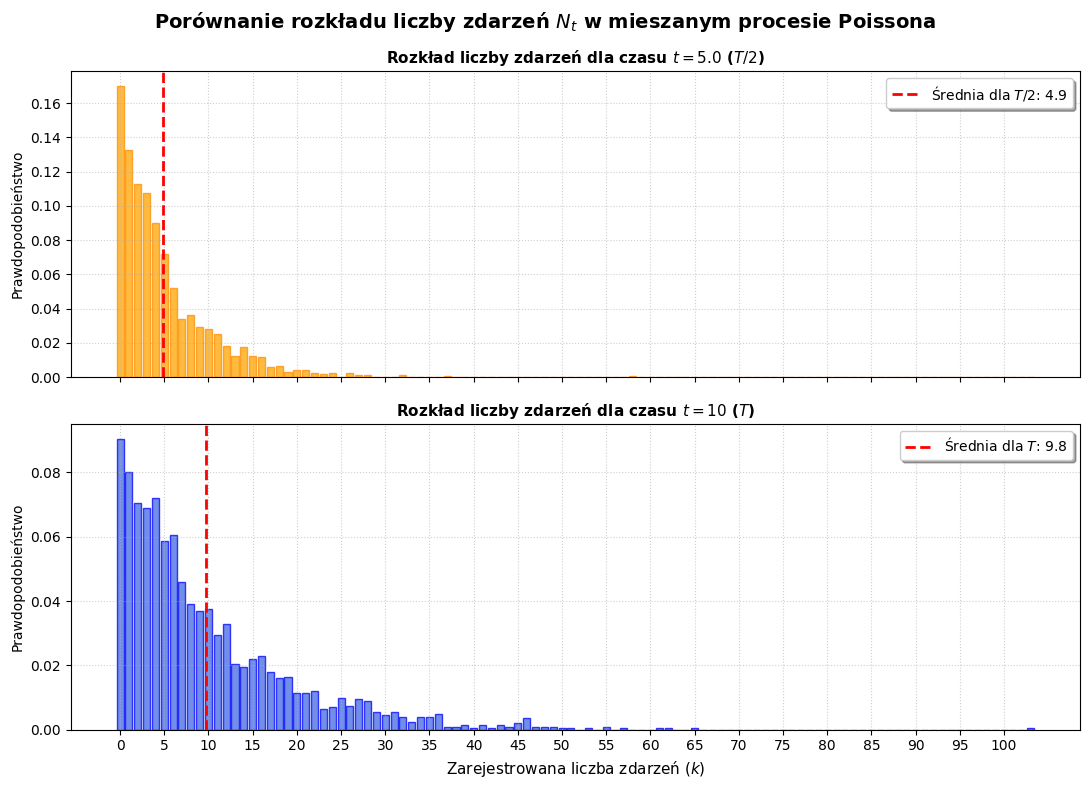

In [ ]:
K = 2000
T = 10

S_all, N_all, path_ids, n_per_path = mixed_poisson_exp(num_paths=K, T_max=T)

plt.figure(figsize=(12, 7))

N_events_T = []
N_events_T_2 = []
for path_id in range(K):

    # for T 
    mask = path_ids == path_id
    S_path = S_all[mask]
    N_path = N_all[mask]
    if len(N_path) > 0:
        N_events_T.append(N_path[-1])
    else:
        N_events_T.append(0)

    # for T/2
    mask_T_2 = S_path < T/2
    S_path = S_path[mask_T_2]
    N_path = N_path[mask_T_2]
    if len(N_path) > 0:
        N_events_T_2.append(N_path[-1])
    else:
        N_events_T_2.append(0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

max_val = max(max(N_events_T), max(N_events_T_2))
bins = np.arange(0, max_val + 2) - 0.5
ticks_step = 2 if max_val < 30 else 5

# --- PIERWSZY WYKRES: Czas T/2 ---
ax1.hist(N_events_T_2, bins=bins, density=True, color='orange', 
         edgecolor='darkorange', alpha=0.75, rwidth=0.8)
ax1.axvline(np.mean(N_events_T_2), color='red', linestyle='--', linewidth=2, 
            label=f'Średnia dla $T/2$: {np.mean(N_events_T_2):.1f}')

ax1.set_title(f"Rozkład liczby zdarzeń dla czasu $t = {T/2}$ ($T/2$)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Prawdopodobieństwo", fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, shadow=True)

ax2.hist(N_events_T, bins=bins, density=True, color='royalblue', 
         edgecolor='blue', alpha=0.75, rwidth=0.8)
ax2.axvline(np.mean(N_events_T), color='red', linestyle='--', linewidth=2, 
            label=f'Średnia dla $T$: {np.mean(N_events_T):.1f}')

ax2.set_title(f"Rozkład liczby zdarzeń dla czasu $t = {T}$ ($T$)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Zarejestrowana liczba zdarzeń ($k$)", fontsize=11)
ax2.set_ylabel("Prawdopodobieństwo", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, shadow=True)

plt.xticks(np.arange(0, max_val + 1, step=ticks_step))

plt.suptitle("Porównanie rozkładu liczby zdarzeń $N_t$ w mieszanym procesie Poissona", fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout()
plt.show()

Lambda jest z rozkładu pareto (z parametrem 2)

676


<Figure size 3000x700 with 0 Axes>

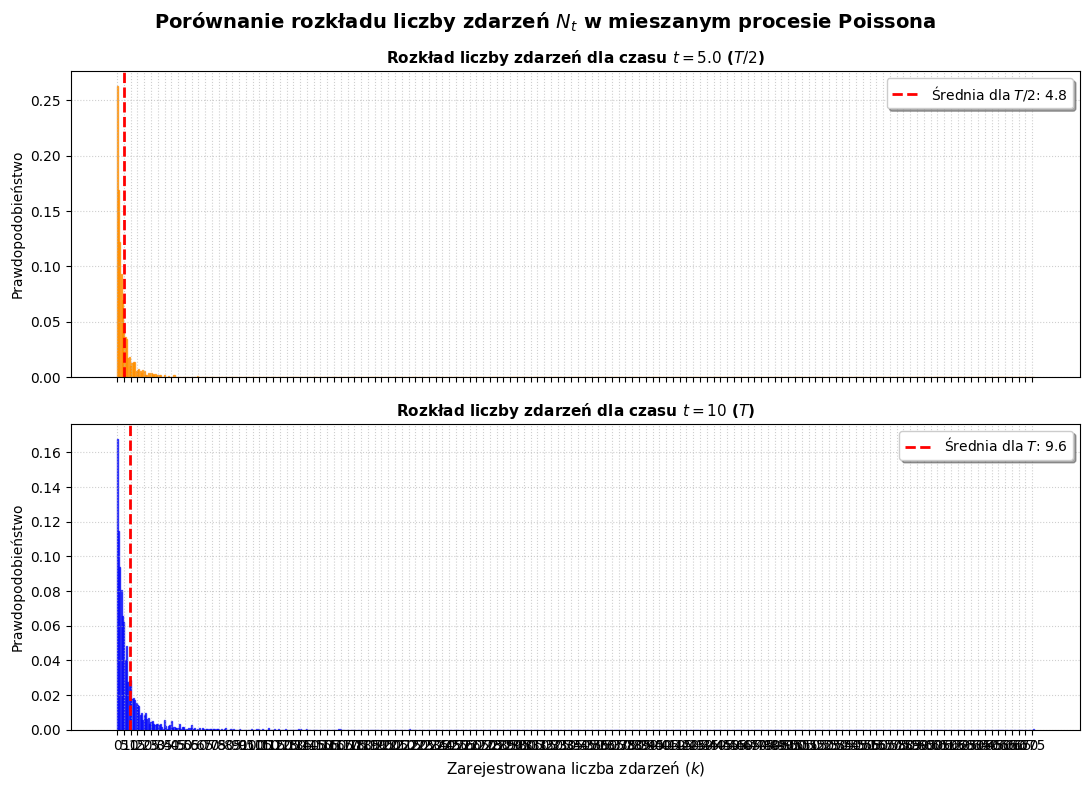

In [ ]:
K = 2000
T = 10

S_all, N_all, path_ids, n_per_path = mixed_poisson_pareto(num_paths=K, T_max=T)

plt.figure(figsize=(30, 7))

N_events_T = []
N_events_T_2 = []
for path_id in range(K):

    # for T 
    mask = path_ids == path_id
    S_path = S_all[mask]
    N_path = N_all[mask]
    if len(N_path) > 0:
        N_events_T.append(N_path[-1])
    else:
        N_events_T.append(0)

    # for T/2
    mask_T_2 = S_path < T/2
    S_path = S_path[mask_T_2]
    N_path = N_path[mask_T_2]
    if len(N_path) > 0:
        N_events_T_2.append(N_path[-1])
    else:
        N_events_T_2.append(0)
print(max(N_events_T))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

max_val = max(max(N_events_T), max(N_events_T_2))
bins = np.arange(0, max_val + 2) - 0.5
ticks_step = 2 if max_val < 30 else 5

ax1.hist(N_events_T_2, bins=bins, density=True, color='orange', 
         edgecolor='darkorange', alpha=0.75, rwidth=0.8)
ax1.axvline(np.mean(N_events_T_2), color='red', linestyle='--', linewidth=2, 
            label=f'Średnia dla $T/2$: {np.mean(N_events_T_2):.1f}')

ax1.set_title(f"Rozkład liczby zdarzeń dla czasu $t = {T/2}$ ($T/2$)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Prawdopodobieństwo", fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, shadow=True)

ax2.hist(N_events_T, bins=bins, density=True, color='royalblue', 
         edgecolor='blue', alpha=0.75, rwidth=0.8)
ax2.axvline(np.mean(N_events_T), color='red', linestyle='--', linewidth=2, 
            label=f'Średnia dla $T$: {np.mean(N_events_T):.1f}')

ax2.set_title(f"Rozkład liczby zdarzeń dla czasu $t = {T}$ ($T$)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Zarejestrowana liczba zdarzeń ($k$)", fontsize=11)
ax2.set_ylabel("Prawdopodobieństwo", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, shadow=True)

plt.xticks(np.arange(0, max_val + 1, step=ticks_step))

plt.suptitle("Porównanie rozkładu liczby zdarzeń $N_t$ w mieszanym procesie Poissona", fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout()
plt.show()

## Interpretacja 
Możemy oszacować rozkład $ N_{T}$ metodami monte carlo. Z histogramów widać, że wybór rozkładu L ma kluczowy wpływ na liczbę zdarzeń w mieszanym procesie Poissona. Rozkład jednostajny $U(0,1)$ daje stabilny histogram bez anomali - (trochę przypomina rozkład jednostajny, poza ostatnią częścią), rozkład wykładniczy daje wartości skoncentrowane przy 1, natomiast rozkład pareto daje wartości bliskie zeru oraz wartości skrajne. 

Spodziewamy się histogramu podobnego do histogramu zmiennej L.

# Zadanie 7. - Ruch Browna

Text(0.5, 1.0, 'Ruch browna 1D')

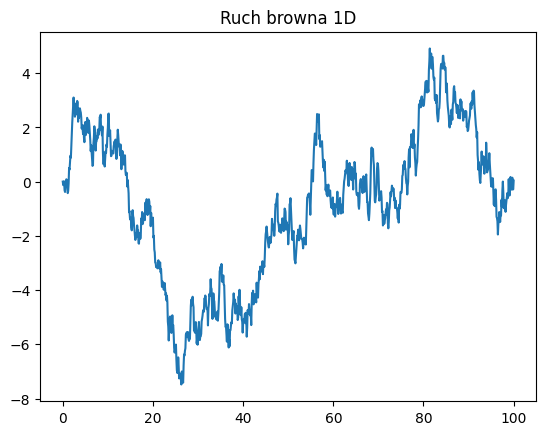

In [74]:
def brown_1d(T_max, n=1000):
    """_summary_

    Args:
        T_max (_type_): max simulation time
        n (int, optional): discrete steps Defaults to 1000.
    """    
    N = np.random.randn(n)
    h = T_max/n # dt ?
    increses = np.concatenate(([0], N * np.sqrt(h)))
    B = np.cumsum(increses)
    T_grid = np.linspace(0,T_max, n+1)
    return B, T_grid

B, grid = brown_1d(100)
plt.plot(grid, B)
plt.title("Ruch browna 1D")

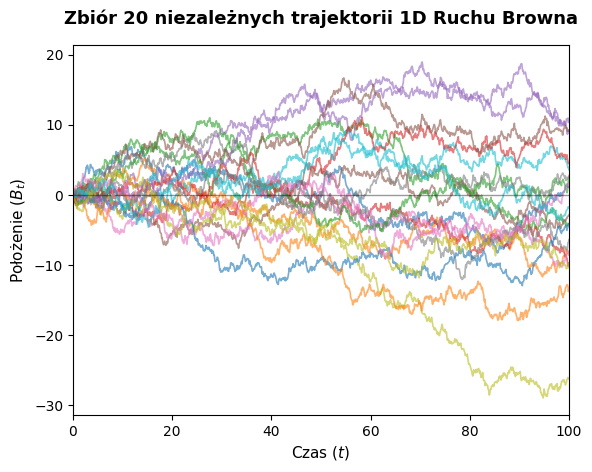

In [80]:
K=20
for i in range(K):
    B, grid = brown_1d(T_max, n=1000)
    
    plt.plot(grid, B, alpha=0.6, linewidth=1.2)


plt.title(f"Zbiór {K} niezależnych trajektorii 1D Ruchu Browna", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Czas ($t$)", fontsize=11)
plt.ylabel("Położenie ($B_t$)", fontsize=11)


plt.xlim(0, T_max)


plt.axhline(0, color='black', linestyle='-', alpha=0.4, linewidth=1)

Text(0.5, 1.0, 'Ruch browna 2D')

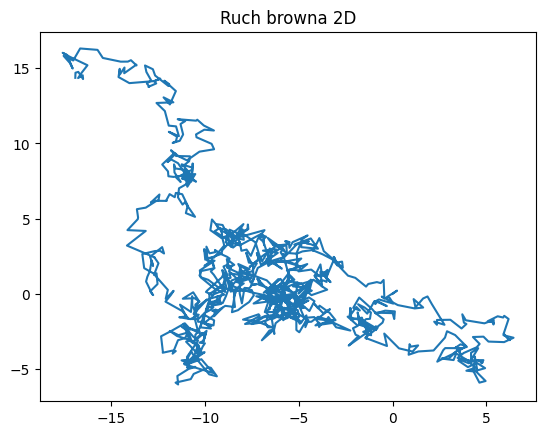

In [81]:
def brown_2d(T_max, n=1000):
    N_1 = np.random.randn(n)
    N_2 = np.random.randn(n)
    h = T_max/n # dt ?
    increses_N1 = np.concatenate(([0], N_1 * np.sqrt(h)))
    increses_N2 = np.concatenate(([0], N_2 * np.sqrt(h)))
    B_x = np.cumsum(increses_N1)
    B_y = np.cumsum(increses_N2)
    return B_x, B_y

B_x, B_y = brown_2d(200)
plt.plot(B_x, B_y)
plt.title("Ruch browna 2D")

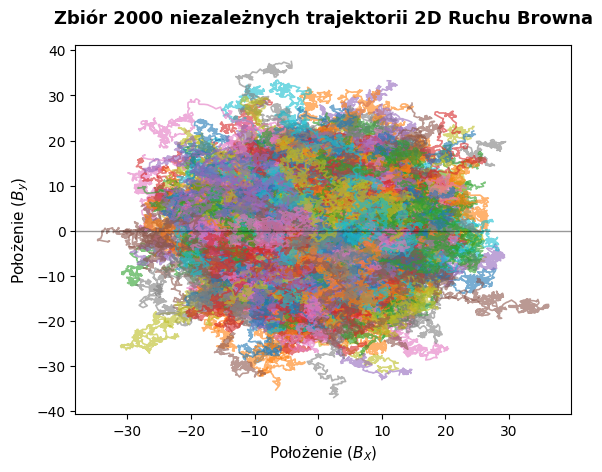

In [93]:
K=2000
for i in range(K):
    B_x, B_y = brown_2d(T_max, n=1000)
    
    plt.plot(B_x, B_y, alpha=0.6, linewidth=1.2)


plt.title(f"Zbiór {K} niezależnych trajektorii 2D Ruchu Browna", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Położenie ($B_X$)", fontsize=11)
plt.ylabel("Położenie ($B_y$)", fontsize=11)

plt.axhline(0, color='black', linestyle='-', alpha=0.4, linewidth=1)

# Zadanie 8. 

In [94]:
T_max=100
B, T_grid = brown_1d(T_max)
trajectories = 1000
time_stamps = [i * T_max/10 for i in range(1, 11)]
means = {}
for i in time_stamps:
    means[i] = []


for i in range(trajectories):
    B, T_grid = brown_1d(T_max)
    for j in time_stamps:
        mask = T_grid < j 
        B_ = B[mask]
        means[j].append(np.var(B_))
    



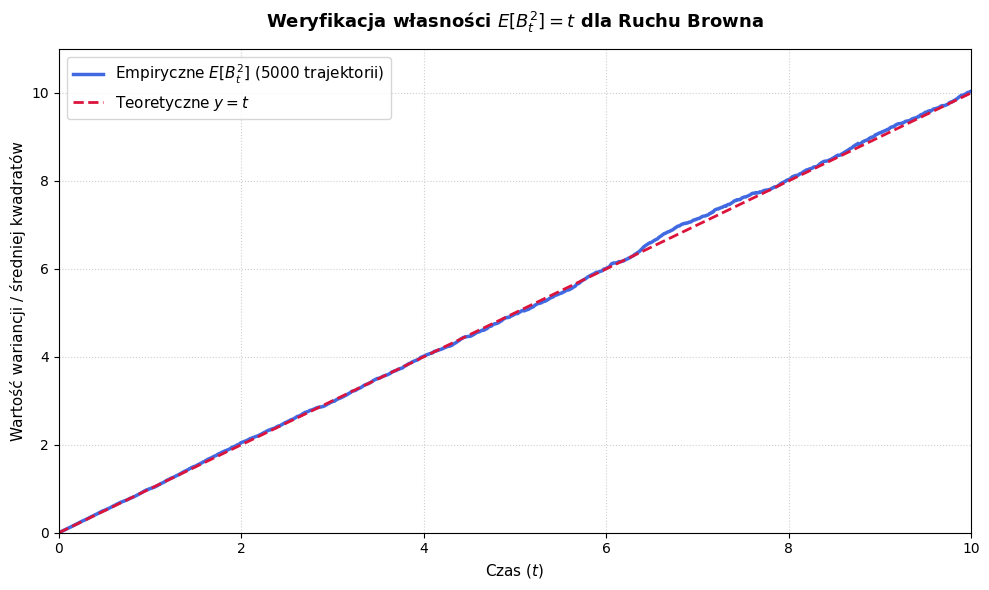

In [ ]:
K = 5000       
T_max = 10      
n_steps = 1000 


all_trajectories = np.zeros((K, n_steps + 1))
_, T_grid = brown_1d(T_max, n=n_steps) # pobieramy siatkę czasu raz

for i in range(K):
    B, _ = brown_1d(T_max, n=n_steps)
    all_trajectories[i, :] = B


squared_trajectories = all_trajectories ** 2

empiric_variance = np.mean(squared_trajectories, axis=0)

plt.figure(figsize=(10, 6))

plt.plot(T_grid, empiric_variance, color='royalblue', linewidth=2.5, 
         label=f'Empiryczne $E[B_t^2]$ ({K} trajektorii)')

plt.plot(T_grid, T_grid, color='crimson', linestyle='--', linewidth=2, 
         label='Teoretyczne $y = t$')

plt.title("Weryfikacja własności $E[B_t^2] = t$ dla Ruchu Browna", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Czas ($t$)", fontsize=11)
plt.ylabel("Wartość wariancji / średniej kwadratów", fontsize=11)
plt.xlim(0, T_max)
plt.ylim(0, T_max + 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

In [96]:
print(np.zeros((K, n_steps + 1)))

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


## Zadanie 9. 
Most Browna 


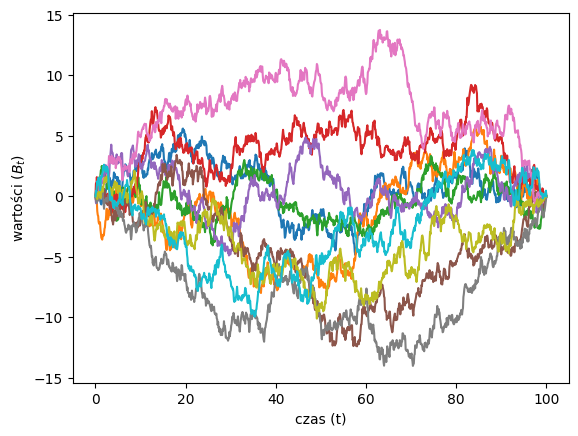

In [126]:
def brown_bridge(T_max, trajectories=10, n=1000, plot=True):
    """_summary_

    Args:
        T_max (_type_): _description_
        trajectories (int, optional): _description_. Defaults to 10.
        n (int, optional): _description_. Defaults to 1000.
    """    
    results = np.zeros((trajectories, n + 1))
    for i in range(trajectories):
        B, T_grid = brown_1d(T_max, n=n)
        BB = B - T_grid / T_max * B[-1]
        results[i, :] = BB
        if plot:
            plt.plot(T_grid, BB)
            plt.xlabel("czas (t)")
            plt.ylabel("wartości ($B_{t}$)")
    
    return results, T_grid
    

results, T_grid = brown_bridge(100, trajectories=10)




Porównanie wariancji 

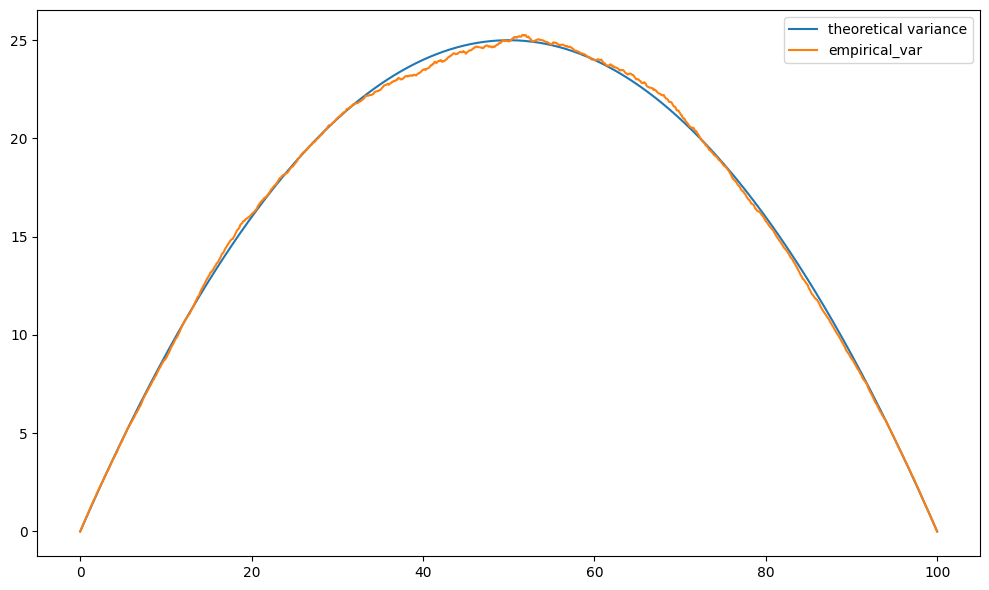

In [131]:
T_max = 100
results, T_grid = brown_bridge(T_max, trajectories=10000, plot=False)

empirical_var = np.var(results, axis=0)
theoretical_var = T_grid * (T_max - T_grid)/T_max

plt.figure(figsize=(10, 6))

plt.plot(T_grid, theoretical_var, label="theoretical variance")
plt.plot(T_grid, empirical_var, label="empirical_var")
plt.title("Porównanie wariancji teoretycznej z empiryczną")
plt.legend()
plt.tight_layout()

<>:39: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:48: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:39: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:48: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\karol\AppData\Local\Temp\ipykernel_1232\72861302.py:39: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ax1.set_title(f"Trajektorie Procesu Gamma ($\lambda = {lam}$)", fontsize=11, fontweight='bold')
C:\Users\karol\AppData\Local\Temp\ipykernel_1232\72861302.py:48: SyntaxWar

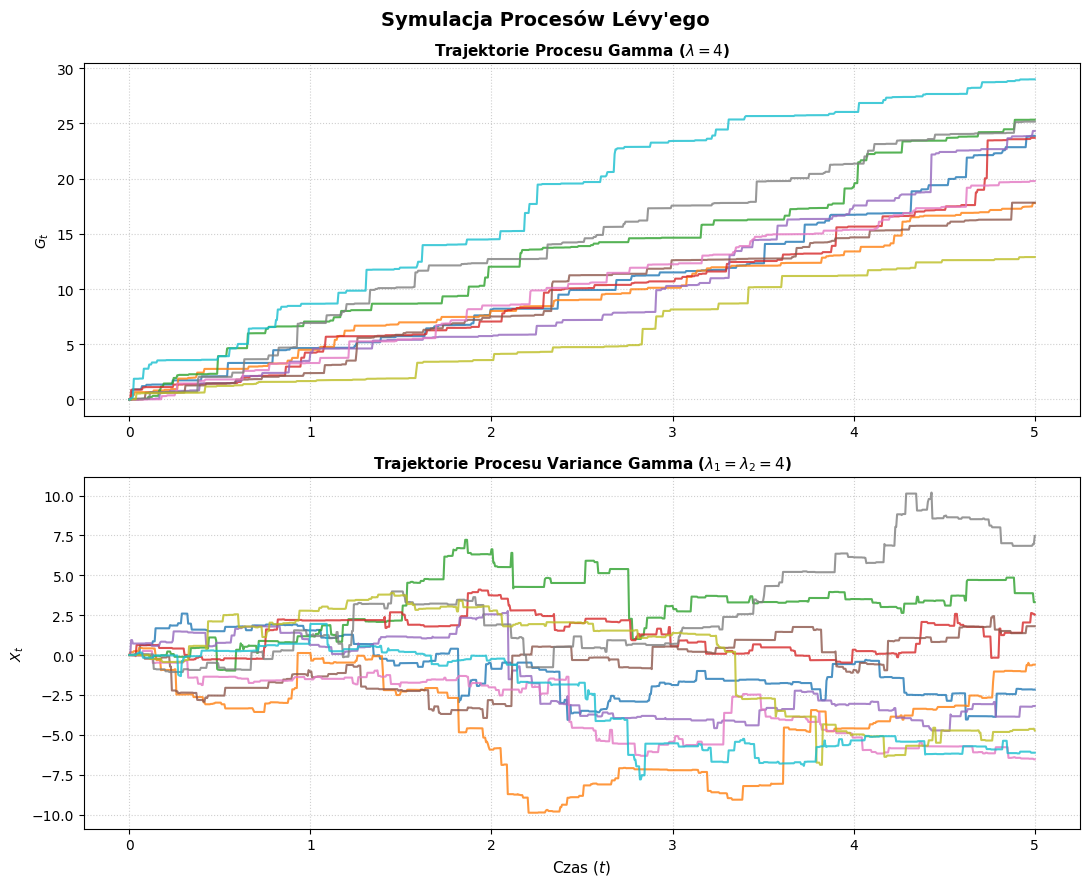

In [136]:
def gamma_process(T_max, lambda_param, n=1000):

    h = T_max / n
    T_grid = np.linspace(0, T_max, n + 1)
    
    # Kształt (shape) przyrostu to lambda * h
    shape_param = lambda_param * h
    
    # Losujemy przyrosty (pierwszy punkt to zawsze 0)
    increments = np.random.gamma(shape=shape_param, scale=1.0, size=n)
    G = np.concatenate(([0], increments))
    
    return np.cumsum(G), T_grid


def variance_gamma_process(T_max, lambda_1, lambda_2, n=1000):
    """
    Variance Gamma process as a difference of two independent Gamma processes
    """
    G1, T_grid = gamma_process(T_max, lambda_param=lambda_1, n=n)
    G2, _ = gamma_process(T_max, lambda_param=lambda_2, n=n)
    
    X = G1 - G2
    return X, T_grid


T_max = 5
n_steps = 1000
K_trajectories = 10
lam = 4             


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9))

# gamma
for i in range(K_trajectories):
    G_path, grid = gamma_process(T_max, lambda_param=lam, n=n_steps)
    ax1.plot(grid, G_path, alpha=0.8, linewidth=1.5)
ax1.set_title(f"Trajektorie Procesu Gamma ($\lambda = {lam}$)", fontsize=11, fontweight='bold')
ax1.set_ylabel("$G_t$", fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)

#  Variance Gamma
for i in range(K_trajectories):
    
    VG_path, grid = variance_gamma_process(T_max, lambda_1=lam, lambda_2=lam, n=n_steps)
    ax2.plot(grid, VG_path, alpha=0.8, linewidth=1.5)
ax2.set_title(f"Trajektorie Procesu Variance Gamma ($\lambda_1 = \lambda_2 = {lam}$)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Czas ($t$)", fontsize=11)
ax2.set_ylabel("$X_t$", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Symulacja Procesów Lévy'ego", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

#### Porównanie z ruchem browna
Proces variance gamma przy dużej liczbie trajektorii na wykresie przypomina kształtem proces wienera ale jak przyjrzymy się  pojedyńczym trajektoriom to widzimy że procesy gamma są skokowe natomiast proces wienera jest ciągły a my go tylko dyskretyzujemy. 

# Zadanie 11. 
Geometryczny ruch browna

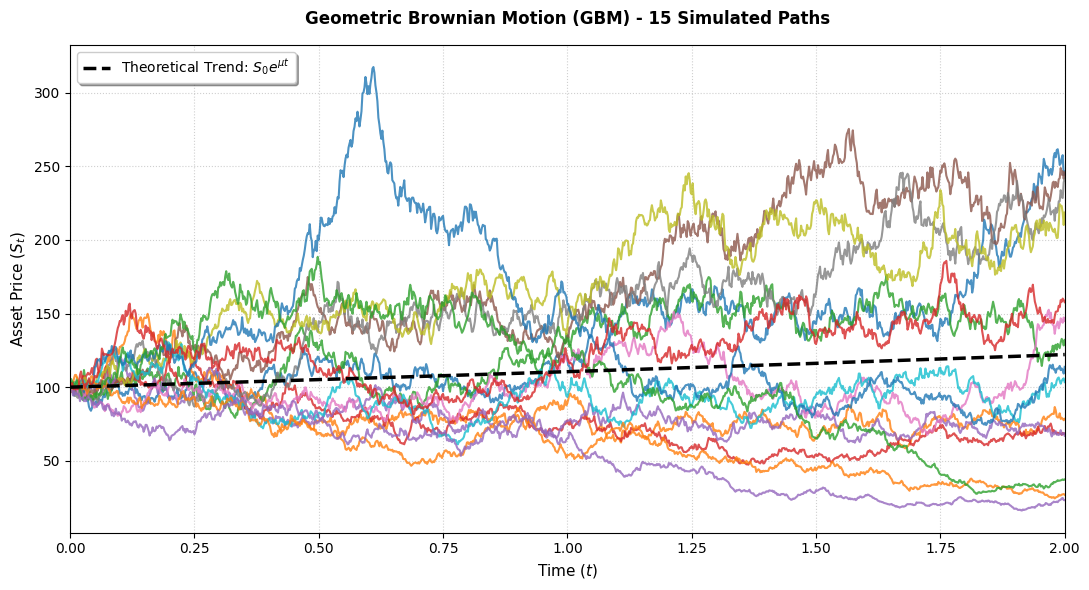

In [164]:
def GBM(S0, mu, sigma, T_max, n, num_trajectories):
    trajectories = np.zeros((num_trajectories, n + 1))
    for i in range(num_trajectories):
        B, T_grid = brown_1d(T_max, n=n)
        S_t = S0 * np.exp((mu - np.power(sigma,2)/2) * T_grid + sigma * B)
        trajectories[i,:]= S_t

    return trajectories, T_grid

initial_price = 100         # S0
drift = 0.1                 # mu (expected annual return)
volatility = 0.25           # sigma (asset volatility)
time_horizon = 2            # T_max (e.g., 2 years)
steps = 1000                # n (number of time steps)
num_paths = 15              # M (number of simulated trajectories)


price_matrix, time_grid = GBM(initial_price, drift, volatility, time_horizon, steps, num_paths)

plt.figure(figsize=(11, 6))

# Plot all simulated asset paths
for i in range(num_paths):
    plt.plot(time_grid, price_matrix[i, :], alpha=0.8, linewidth=1.5)

theoretical_trend = initial_price * np.exp(drift * time_grid)
plt.plot(time_grid, theoretical_trend, color='black', linestyle='--', linewidth=2.5, 
         label=r'Trend teoretyczny: $S_0 e^{\mu t}$')


plt.title(f"Geometryczny ruch browna (GBM) - {num_paths} Trajektorii", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("czas ($t$)", fontsize=11)
plt.ylabel("Cena ($S_t$)", fontsize=11)
plt.xlim(0, time_horizon)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, shadow=True)

plt.tight_layout()
plt.show()


Text(0, 0.5, 'Gestość prawdopodobieństwa')

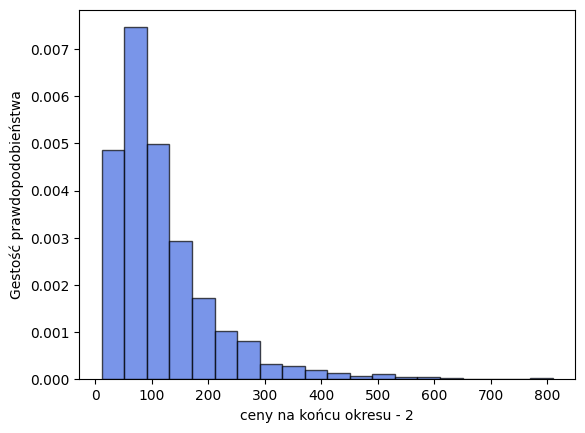

In [174]:
num_paths = 1000
price_matrix, time_grid = GBM(initial_price, drift, volatility, time_horizon, steps, num_paths)
last_el = price_matrix[:,-1]
plt.hist(last_el, density=True, bins=20,color='royalblue', edgecolor='black', alpha=0.7)
plt.xlabel(f"ceny na końcu okresu - {time_horizon}")
plt.ylabel(f"Gestość prawdopodobieństwa")

## Zadanie 12. 

In [ ]:
import yfinance as yf
import pandas as pd 

oracle = yf.download("ORCL", start="2022-01-01", end="2026-06-20", progress=False)
oracle.head()


Price,Close,High,Low,Open,Volume
Ticker,ORCL,ORCL,ORCL,ORCL,ORCL
Date,,,,,
2022-01-03,82.743179,82.780834,80.728727,82.206620,10644400
2022-01-04,83.628044,84.324636,82.583171,82.743196,11959000
2022-01-05,81.387680,83.402133,81.161762,83.298586,11236700
2022-01-06,81.576660,82.597079,80.830250,81.255421,7918400
2022-01-07,82.682091,83.145056,81.519946,81.680566,9836800


In [ ]:
# 
cutoff_date = '2024-03-24'

historical_prices = oracle.loc[oracle.index <= cutoff_date, ("Close", "ORCL")]

close_prices = oracle.loc[:, ("Close", "ORCL")]

# annualized parameters
log_returns = np.log(historical_prices / historical_prices.shift(1)).dropna()
mu_calibrated = log_returns.mean() * 252
sigma_calibrated = log_returns.std() * np.sqrt(252)

# initial price at  24.03.2025
S0_backtest = historical_prices.iloc[-1]

print("--- Kalibracja modelu (dane do 24.03.2025) ---")
print(f"Cena startowa (S0):        {S0_backtest:.2f} USD")
print(f"Wyliczony dryf (mu):       {mu_calibrated:.4f} (annually)")
print(f"Wyliczona zmienność (sig): {sigma_calibrated:.4f} (annually)\n")


--- Kalibracja modelu (dane do 24.03.2025) ---
Cena startowa (S0):        124.72 USD
Wyliczony dryf (mu):       0.1856 (rocznie)
Wyliczona zmienność (sig): 0.3075 (rocznie)



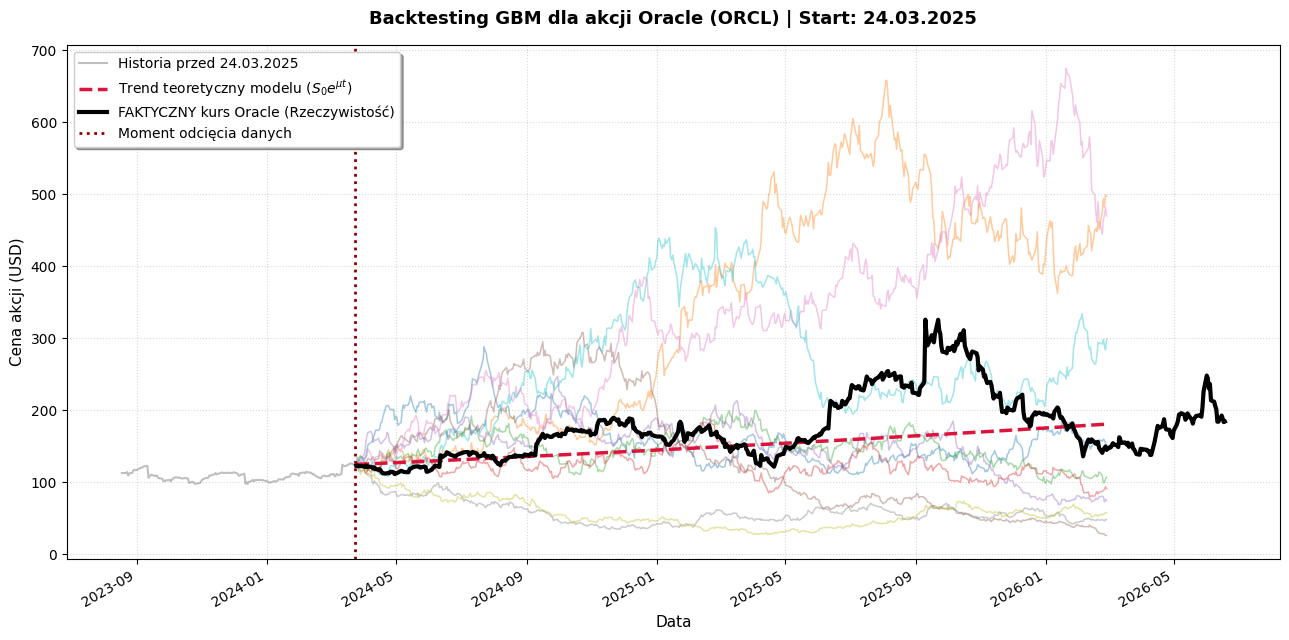

In [ ]:
# Simulation for the next 2 years
time_horizon = 2.0       # 2 years
num_days = 504           # 2 years * 252 business days
num_trajectories = 100   # num of paths to generate
paths_to_plot = 10       # num of paths to plot

price_matrix, time_grid = GBM(S0_backtest, mu_calibrated, sigma_calibrated, time_horizon, num_days, num_trajectories)

future_dates = pd.date_range(start=cutoff_date, periods=num_days + 1, freq='B')

actual_future_prices = oracle.loc[oracle.index >= cutoff_date, ("Close", "ORCL")]


plt.figure(figsize=(13, 6.5))

# historical prices before the forecast
plt.plot(historical_prices.index[-150:], historical_prices.values[-150:], 
         color='gray', alpha=0.5, label='Historia przed 24.03.2025')

# simulated future
for i in range(paths_to_plot):
    plt.plot(future_dates, price_matrix[i, :], alpha=0.4, linewidth=1.1)

# theoretical expected trend
theoretical_trend = S0_backtest * np.exp(mu_calibrated * time_grid)
plt.plot(future_dates, theoretical_trend, color='crimson', linestyle='--', linewidth=2.5,
         label=r'Trend teoretyczny modelu ($S_0 e^{\mu t}$)')

# ploting the ACTUAL prices for that period
plt.plot(actual_future_prices.index, actual_future_prices.values, 
         color='black', linewidth=3, label='FAKTYCZNY kurs Oracle (Rzeczywistość)')

# titles etc
plt.title("Backtesting GBM dla akcji Oracle (ORCL) | Start: 24.03.2025", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Data", fontsize=11)
plt.ylabel("Cena akcji (USD)", fontsize=11)

# forecast start 
plt.axvline(x=pd.to_datetime(cutoff_date), color='darkred', linestyle=':', linewidth=2, label='Moment odcięcia danych')

plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.gcf().autofmt_xdate() 

plt.tight_layout()
plt.show()